# Best-Selling Music Artists: Scraping and Analysis

Scrapes the tables of Wikipedia's *List of best-selling music artists* with BeautifulSoup, cleans them into a tidy table, then compares certified and claimed sales across eras, genres, careers and countries (the last part in SQL).

Save a copy of the Wikipedia page as `best_selling_artists.html` in this folder before running.

## Setup

In [1]:
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from bs4 import BeautifulSoup

with open("best_selling_artists.html", encoding="utf-8") as f:
    soup = BeautifulSoup(f, "html.parser")

## 1. Scrape and clean the best-selling artists tables

In [2]:
def make_tier(heading):
    numbers = re.findall(r"\d+", heading)
    if "or more" in heading:
        return numbers[0] + "M+"
    return numbers[0] + "-" + numbers[1] + "M"

def parse_sales(text):
    text = text.replace(",", "")
    region = re.search(r"\b[A-Z]{2,3}\s*:", text)
    if region:
        text = text[:region.start()]
    values = []
    for number in re.findall(r"(\d+(?:\.\d+)?)\s*million", text):
        values.append(float(number))
    return values

rows = []
for table in soup.find_all("table", class_="wikitable"):
    header_text = table.find("tr").get_text(" ", strip=True)
    if "Artist" not in header_text or "Claimed sales" not in header_text:
        continue

    heading = table.find_previous(["h2", "h3"]).get_text(" ", strip=True)
    tier = make_tier(heading)

    for tr in table.find_all("tr")[1:]:
        cells = tr.find_all(["th", "td"], recursive=False)
        if len(cells) != 7:
            continue
        for cell in cells:
            for sup in cell.find_all("sup"):
                sup.decompose()

        certified_values = parse_sales(cells[5].get_text(" ", strip=True))
        claimed_values = parse_sales(cells[6].get_text(" ", strip=True))

        if len(certified_values) > 0:
            certified = certified_values[0]
        else:
            certified = np.nan

        if len(claimed_values) > 0:
            claimed = max(claimed_values)
        else:
            claimed = np.nan

        year_text = cells[3].get_text(" ", strip=True)
        year_match = re.search(r"\d{4}", year_text)
        if year_match:
            first_year = int(year_match.group())
        else:
            first_year = np.nan

        rows.append({
            "artist": cells[0].get_text(" ", strip=True),
            "country": " / ".join(cells[1].stripped_strings),
            "period_active": cells[2].get_text(" ", strip=True),
            "first_charted_year": first_year,
            "genre": cells[4].get_text(" ", strip=True),
            "certified_units_m": certified,
            "claimed_sales_m": claimed,
            "tier": tier
        })

q1_df = pd.DataFrame(rows, columns=["artist", "country", "period_active", "first_charted_year", "genre",
                                    "certified_units_m", "claimed_sales_m", "tier"])
print(q1_df["tier"].value_counts(sort=False).to_string())
print()

q1_n_rows = len(q1_df)
q1_certified_dtype = str(q1_df["certified_units_m"].dtype)
q1_claimed_dtype = str(q1_df["claimed_sales_m"].dtype)
q1_missing_certified = int(q1_df["certified_units_m"].isna().sum())
q1_missing_claimed = int(q1_df["claimed_sales_m"].isna().sum())
q1_head = q1_df.head()

print("row count:", q1_n_rows)
print("dtypes:", q1_certified_dtype, "/", q1_claimed_dtype)
print("missing  certified:", q1_missing_certified, " claimed:", q1_missing_claimed)
q1_head

tier
250M+        9
200-249M    10
120-199M    30
100-119M    40
80-99M      20
75-79M      19

row count: 128
dtypes: float64 / float64
missing  certified: 0  claimed: 0


,artist,country,period_active,first_charted_year,genre,certified_units_m,claimed_sales_m,tier
0,The Beatles,United Kingdom,1960–1970,1962,Rock / pop,295.9,600.0,250M+
1,Michael Jackson,United States,1964–2009,1971,R&B / pop,305.5,500.0,250M+
2,Elvis Presley,United States,1953–1977,1956,Rock / pop / country / gospel,235.4,500.0,250M+
3,Elton John,United Kingdom,1962–present,1970,Pop / rock,216.8,300.0,250M+
4,Queen,United Kingdom,1971–present,1973,Rock / pop,201.1,300.0,250M+


**Interpretation**

**Answer key.** Provide your answer in this cell.
The page has 11 tables, but only 6 of them are artist listings. I kept only the `wikitable` tables whose header row contains both "Artist" and "Claimed sales", which drops the navigation boxes at the bottom of the page. Each table's tier label is taken from the heading just above it: "250 million or more records" becomes "250M+", and headings of the form "200 million to 249 million records" become "200-249M". Inside each table, I skipped one empty spacer row and removed every `<sup>` tag before reading the text, which strips citation markers such as [11] and [b]. For the sales columns, I removed commas, cut the text at the first regional tag (such as "US:" or "JPN:") so that only the worldwide figure is left, and then picked out every number followed by "million". Certified units uses the first number, and claimed sales uses the highest number when several competing claims are listed (for example, "600 million 500 million" for The Beatles becomes 600). A cell with no usable number would be left as NaN.

The final table has 128 rows, one per artist, split across the tiers as 9 (250M+), 10 (200-249M), 30 (120-199M), 40 (100-119M), 20 (80-99M) and 19 (75-79M). Both certified_units_m and claimed_sales_m are float64, with 0 missing values in each. The first five rows are The Beatles, Michael Jackson, Elvis Presley, Elton John and Queen, and all the provided checks pass, including Taylor Swift's worldwide certified total of 348.4 and highest claim of 200.0.

## 2. Certified vs claimed sales by era

artists with both figures: 128

overall ratio
count    128.000
mean       0.917
std        0.635
min        0.070
25%        0.492
50%        0.722
75%        1.092
max        4.000
artists with ratio above 1 (certified > claimed): 38 of 128

ratio by decade of first charted record
 decade  artists  median_ratio  mean_ratio  share_above_1_%
   1940        1         0.279       0.279              0.0
   1950        2         0.414       0.414              0.0
   1960       29         0.485       0.505              0.0
   1970       29         0.633       0.612              3.4
   1980       20         0.765       0.769             20.0
   1990       22         0.921       1.074             45.5
   2000       18         1.404       1.520             88.9
   2010        7         2.396       2.505            100.0

ratio by country (countries with at least 5 artists)
       country  artists  median_ratio  median_first_year  share_since_2000_%
 United States       83         0.773         

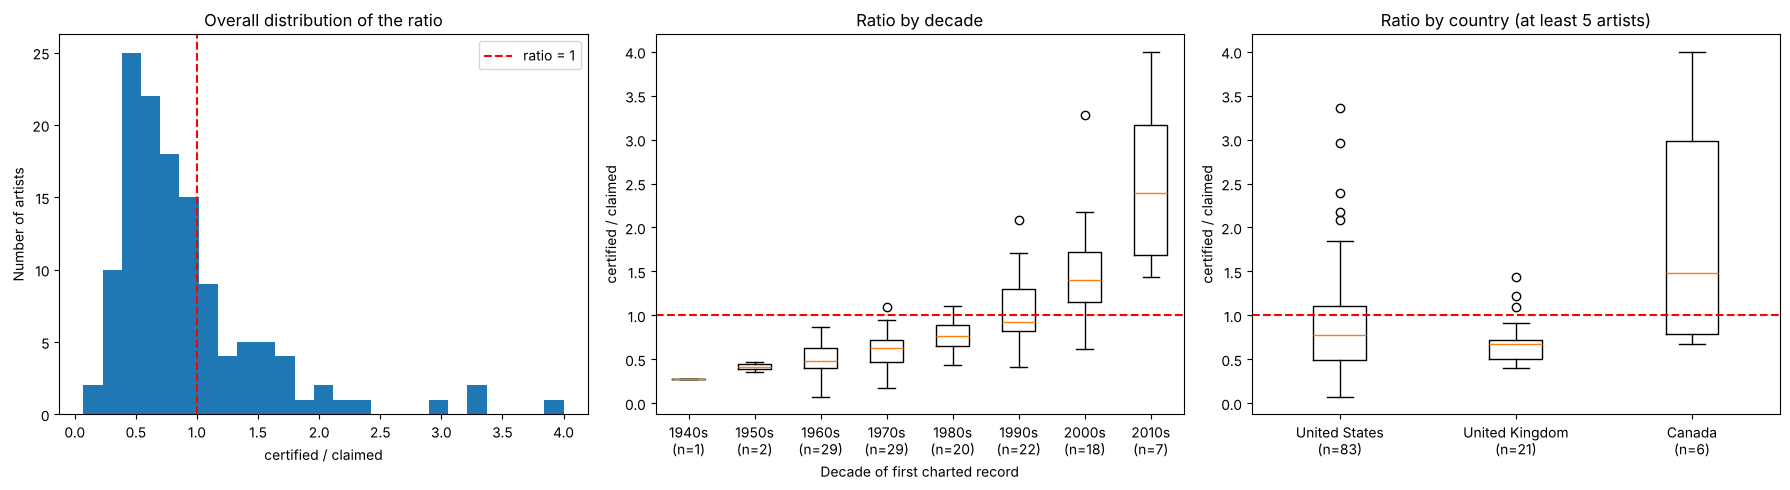

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

df = q1_df.copy()   # the assembled table from Q1

both = df[df["certified_units_m"].notna() & df["claimed_sales_m"].notna()].copy()
both["ratio"] = both["certified_units_m"] / both["claimed_sales_m"]
both["decade"] = (both["first_charted_year"] // 10) * 10
print(f"artists with both figures: {len(both)}")

print("\noverall ratio")
print(both["ratio"].describe().round(3).to_string())
print(f"artists with ratio above 1 (certified > claimed): {(both['ratio'] > 1).sum()} of {len(both)}")

decade_rows = []
for d in sorted(both["decade"].unique()):
    group = both[both["decade"] == d]
    decade_rows.append({
        "decade": int(d),
        "artists": len(group),
        "median_ratio": round(group["ratio"].median(), 3),
        "mean_ratio": round(group["ratio"].mean(), 3),
        "share_above_1_%": round((group["ratio"] > 1).mean() * 100, 1)
    })
decade_table = pd.DataFrame(decade_rows)
print("\nratio by decade of first charted record")
print(decade_table.to_string(index=False))

min_artists = 5
country_counts = both["country"].value_counts()
big_countries = country_counts[country_counts >= min_artists].index.tolist()
country_rows = []
for c in big_countries:
    group = both[both["country"] == c]
    country_rows.append({
        "country": c,
        "artists": len(group),
        "median_ratio": round(group["ratio"].median(), 3),
        "median_first_year": int(group["first_charted_year"].median()),
        "share_since_2000_%": round((group["first_charted_year"] >= 2000).mean() * 100, 1)
    })
country_table = pd.DataFrame(country_rows)
print(f"\nratio by country (countries with at least {min_artists} artists)")
print(country_table.to_string(index=False))

era_list = []
for y in both["first_charted_year"]:
    if y < 1990:
        era_list.append("before 1990")
    else:
        era_list.append("1990 onwards")
both["era"] = era_list

era_rows = []
for c in big_countries:
    for era in ["before 1990", "1990 onwards"]:
        group = both[(both["country"] == c) & (both["era"] == era)]
        if len(group) > 0:
            era_rows.append({
                "country": c,
                "era": era,
                "artists": len(group),
                "median_ratio": round(group["ratio"].median(), 3)
            })
print("\nratio by country within the same era")
print(pd.DataFrame(era_rows).to_string(index=False))

print(f"\ncorrelation of ratio with first charted year: {both['ratio'].corr(both['first_charted_year']):.3f}")

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

axes[0].hist(both["ratio"], bins=25)
axes[0].axvline(1, color="red", linestyle="--", label="ratio = 1")
axes[0].set_xlabel("certified / claimed")
axes[0].set_ylabel("Number of artists")
axes[0].set_title("Overall distribution of the ratio")
axes[0].legend()

decade_data = []
decade_labels = []
for d in sorted(both["decade"].unique()):
    decade_data.append(both[both["decade"] == d]["ratio"])
    decade_labels.append(f"{int(d)}s\n(n={len(both[both['decade'] == d])})")
axes[1].boxplot(decade_data)
axes[1].set_xticks(range(1, len(decade_labels) + 1))
axes[1].set_xticklabels(decade_labels)
axes[1].axhline(1, color="red", linestyle="--")
axes[1].set_xlabel("Decade of first charted record")
axes[1].set_ylabel("certified / claimed")
axes[1].set_title("Ratio by decade")

country_data = []
country_labels = []
for c in big_countries:
    country_data.append(both[both["country"] == c]["ratio"])
    country_labels.append(f"{c}\n(n={country_counts[c]})")
axes[2].boxplot(country_data)
axes[2].set_xticks(range(1, len(country_labels) + 1))
axes[2].set_xticklabels(country_labels)
axes[2].axhline(1, color="red", linestyle="--")
axes[2].set_ylabel("certified / claimed")
axes[2].set_title(f"Ratio by country (at least {min_artists} artists)")

plt.tight_layout()
plt.show()

## 3. Sales by genre

In [4]:
import numpy as np
import pandas as pd

sales_col = "claimed_sales_m"

genre_rows = []
for index, row in q1_df.iterrows():
    tokens = row["genre"].split("/")
    for token in tokens:
        clean = token.strip().lower()
        if clean != "":
            genre_rows.append({"artist": row["artist"], "genre": clean, sales_col: row[sales_col]})
genre_long = pd.DataFrame(genre_rows)
genre_long = genre_long.drop_duplicates(subset=["artist", "genre"])

raw_tokens = set()
for g in q1_df["genre"]:
    for token in g.split("/"):
        raw_tokens.add(token.strip())
print(f"distinct genre tokens before normalising: {len(raw_tokens)}")
print(f"distinct genres after normalising: {genre_long['genre'].nunique()}")
print(sorted(genre_long["genre"].unique()))

rank_rows = []
for g in genre_long["genre"].unique():
    group = genre_long[genre_long["genre"] == g]
    rank_rows.append({
        "genre": g,
        "n_acts": len(group),
        "total_sales_m": group[sales_col].sum(),
        "median_sales_m": group[sales_col].median(),
        "mean_sales_m": round(group[sales_col].mean(), 1),
        "max_sales_m": group[sales_col].max()
    })
genre_table = pd.DataFrame(rank_rows)
genre_table["rank_total"] = genre_table["total_sales_m"].rank(ascending=False, method="min").astype(int)
genre_table["rank_median"] = genre_table["median_sales_m"].rank(ascending=False, method="min").astype(int)
genre_table["rank_change"] = genre_table["rank_total"] - genre_table["rank_median"]

print("\nranking by total claimed sales")
print(genre_table.sort_values("rank_total").to_string(index=False))
print("\nranking by median claimed sales per act")
print(genre_table.sort_values(["rank_median", "genre"]).to_string(index=False))

print(f"\ncorrelation of n_acts with total sales across genres: {genre_table['n_acts'].corr(genre_table['total_sales_m']):.3f}")
print(f"correlation of median sales with total sales across genres: {genre_table['median_sales_m'].corr(genre_table['total_sales_m']):.3f}")

acts_per_artist = genre_long.groupby("artist")["genre"].count()
print(f"\naverage genres per act: {acts_per_artist.mean():.2f}, sum of genre totals: {genre_table['total_sales_m'].sum():.0f}m vs sum of all acts: {q1_df[sales_col].sum():.0f}m")

distinct genre tokens before normalising: 23
distinct genres after normalising: 17
['blues', 'country', 'easy listening', 'electronic', 'folk', 'gospel', 'hip-hop', 'jazz', 'latin', 'metal', 'new-age', 'operatic pop', 'pop', 'r&b', 'reggae', 'rock', 'world']

ranking by total claimed sales
         genre  n_acts  total_sales_m  median_sales_m  mean_sales_m  max_sales_m  rank_total  rank_median  rank_change
           pop      80        11230.0           100.0         140.4        600.0           1            3           -2
          rock      65         8617.0           100.0         132.6        600.0           2            3           -1
           r&b      29         3843.0           100.0         132.5        500.0           3            3            0
       country      12         1700.0           100.0         141.7        500.0           4            3            1
       hip-hop      12         1425.0           110.0         118.8        220.0           5            1         

**Interpretation**

**Answer key.** Provide your answer in this cell.
**Normalising and choices.** Splitting on "/" gives 23 distinct tokens. After stripping spaces and converting to lower case (so that "Pop" and "pop", or "Rock" and "rock", are counted together), this falls to **17 distinct genres**. Each act counts once towards every genre it lists. I used **claimed_sales_m** because Q2 showed that certified units are strongly biased by era: the median certified/claimed ratio is 0.485 for 1960s acts but 2.396 for 2010s acts. Using certified units would therefore undercount genres made up of older acts and overcount streaming-era ones. Claimed sales are unaudited, but they are a worldwide, all-time figure for every act, so they are fairer across eras. For the per-artist statistic I used the **median**, because claimed sales are skewed by a few giants (The Beatles at 600, Elvis Presley and Michael Jackson at 500). Gospel shows the problem: its mean is 177.9 but its median is only 100, because Elvis alone pulls the mean up.

**1. How the ranking changes.** By total sales, the ranking is pop (11,230m from 80 acts), rock (8,617m from 65 acts) and R&B (3,843m from 29 acts). By median, the order flips: hip-hop and metal come joint 1st at 110m, and pop, rock and R&B drop into a large tie for 3rd at 100m. The sharpest mover is metal, which goes from 11th by total (only 4 acts) to joint 1st by median. World falls the other way, from 8th to 13th (median 90m). The two orderings disagree because the total is roughly "number of acts times typical sales", and genres differ hugely in their number of acts (80 for pop against 1 for reggae), while the typical act in almost every genre sits within a narrow band of 75m to 110m.

**2. What drives the total-based ranking.** The number of acts credited to the genre. Across genres, the number of acts has a correlation of 0.999 with total sales, while the median per act has only 0.255. Multi-genre tagging adds to this, because each act lists 1.91 genres on average, so the genre totals add up to 32,469m even though the acts themselves only total 16,730m. Broad labels like pop and rock collect a share of almost every act.

**3. Can we say which genres produce the best-selling artists?** No. This list only contains artists who already claim at least 75 million sales, so it says nothing about how many artists in each genre tried and did not reach that level. A genre could appear high simply because it has far more artists overall, not because its artists are more likely to succeed. What the ranking actually shows is how common each genre label is among today's top sellers, inflated by multi-genre tagging and based on unaudited claims. To support the claim, we would need the full population of artists in each genre, including those below 75 million, so that a success rate or sales distribution could be compared, plus a single consistent primary genre per act and audited sales figures that are comparable across eras.

## 4. Sales per active year

In [5]:
import re
import numpy as np
import pandas as pd

PRESENT_YEAR = 2026

def count_active_years(period):
    text = period.replace("present", str(PRESENT_YEAR))
    total = 0
    spans = re.findall(r"(\d{4})\s*[–-]\s*(\d{4})", text)
    for start, end in spans:
        total = total + (int(end) - int(start) + 1)
    leftover = re.sub(r"\d{4}\s*[–-]\s*\d{4}", " ", text)
    single_years = re.findall(r"\d{4}", leftover)
    total = total + len(single_years)
    if total == 0:
        return np.nan
    return total

q4_df = q1_df.copy()
active_list = []
for p in q4_df["period_active"]:
    active_list.append(count_active_years(p))
q4_df["active_years"] = active_list
q4_df["sales_per_year_m"] = q4_df["claimed_sales_m"] / q4_df["active_years"]

print(f"'present' resolved to {PRESENT_YEAR}")
check_examples = ["1979–present", "1971–1980, 1994–present", "1965–1996, 2005, 2012–2014", "1963–2003 2009–2012"]
for example in check_examples:
    print(f"check: {example} -> {count_active_years(example)} years")
print(f"missing active_years: {q4_df['active_years'].isna().sum()}, missing sales_per_year_m: {q4_df['sales_per_year_m'].isna().sum()}")
print()

print(q4_df[["artist", "period_active", "active_years", "claimed_sales_m",
             "sales_per_year_m"]].head())

'present' resolved to 2026
check: 1979–present -> 48 years
check: 1971–1980, 1994–present -> 43 years
check: 1965–1996, 2005, 2012–2014 -> 36 years
check: 1963–2003 2009–2012 -> 45 years
missing active_years: 0, missing sales_per_year_m: 0

            artist period_active  active_years  claimed_sales_m  \
0      The Beatles     1960–1970            11            600.0   
1  Michael Jackson     1964–2009            46            500.0   
2    Elvis Presley     1953–1977            25            500.0   
3       Elton John  1962–present            65            300.0   
4            Queen  1971–present            56            300.0   

   sales_per_year_m  
0         54.545455  
1         10.869565  
2         20.000000  
3          4.615385  
4          5.357143  


In [6]:
# Rank the artists by sales per active year (artist as a deterministic tiebreak)
q4_ranked = q4_df.dropna(subset=["sales_per_year_m"]).copy()
q4_ranked["total_rank"] = q4_ranked["claimed_sales_m"].rank(ascending=False, method="min").astype(int)
q4_ranked = q4_ranked.sort_values(["sales_per_year_m", "artist"], ascending=[False, True]).reset_index(drop=True)
q4_ranked["per_year_rank"] = q4_ranked.index + 1
q4_ranked["rank_change"] = q4_ranked["total_rank"] - q4_ranked["per_year_rank"]
q4_ranked["sales_per_year_m"] = q4_ranked["sales_per_year_m"].round(2)

top_total = q4_ranked.sort_values(["claimed_sales_m", "artist"], ascending=[False, True]).head(10)
print("top 10 by total claimed sales, with their per-year rank")
print(top_total[["artist", "claimed_sales_m", "active_years", "sales_per_year_m", "total_rank", "per_year_rank"]].to_string(index=False))
print()

q4_rank_pd = q4_ranked.head(10)[["per_year_rank", "artist", "period_active", "active_years", "claimed_sales_m",
                                 "sales_per_year_m", "total_rank", "rank_change"]]

q4_rank_pd

top 10 by total claimed sales, with their per-year rank
         artist  claimed_sales_m  active_years  sales_per_year_m  total_rank  per_year_rank
    The Beatles            600.0            11             54.55           1              1
  Elvis Presley            500.0            25             20.00           2              3
Michael Jackson            500.0            46             10.87           2              6
     Elton John            300.0            65              4.62           4             37
   Led Zeppelin            300.0            13             23.08           4              2
        Madonna            300.0            48              6.25           4             20
          Queen            300.0            56              5.36           4             28
     Pink Floyd            250.0            36              6.94           8             14
        Rihanna            250.0            24             10.42           8              7
         Eminem         

,per_year_rank,artist,period_active,active_years,claimed_sales_m,sales_per_year_m,total_rank,rank_change
0,1,The Beatles,1960–1970,11,600.0,54.55,1,0
1,2,Led Zeppelin,1968–1980,13,300.0,23.08,4,2
2,3,Elvis Presley,1953–1977,25,500.0,20.00,2,-1
3,4,Tupac Shakur,1991–1996,6,75.0,12.50,110,106
4,5,The Doors,1965–1973,9,100.0,11.11,50,45
5,6,Michael Jackson,1964–2009,46,500.0,10.87,2,-4
6,7,Rihanna,2003–present,24,250.0,10.42,8,1
7,8,Nirvana,1987–1994,8,75.0,9.38,110,102
8,9,Ed Sheeran,2004–present,23,200.0,8.70,13,4
9,10,ABBA,"1972–1982, 2016–2022",18,150.0,8.33,26,16


**Interpretation**

**One insight - what the per-year ranking reveals.** Provide your answer in this cell.
"present" was resolved to 2026, and the parser passes the four examples in the question (for example 1965 to 1996, 2005, 2012 to 2014 gives 36 years, and 1963 to 2003 plus 2009 to 2012 gives 45 years), with no missing values. The Beatles stay 1st on both measures, with 600m over just 11 active years (54.55m per year). After that, the per-year ranking reshuffles the total ranking heavily. The act that rises most sharply is Tupac Shakur, who is tied for last on total sales (rank 110, 75m) but 4th per year (12.50m over 6 years). Nirvana makes a similar jump, from 110th to 8th (9.38m over 8 years), and The Doors rise from 50th to 5th (11.11m over 9 years). An act that falls sharply is Elton John, who is joint 4th on total sales with 300m but drops to 37th per year, because he has been active for 65 years (4.62m per year). Queen (4th to 28th) and Madonna (4th to 20th) fall in the same way.

**Insight:** the per-year leaders are mostly acts whose careers ended early through break-ups or deaths, such as The Beatles (1970), Led Zeppelin (1980), The Doors, Nirvana and Tupac. Their records kept selling for decades after they stopped, but their active years stayed fixed, so their sales per year look very high. Long-running acts like Elton John and Queen are diluted by every extra year. So "sales per active year" does not really measure how intensely an act sold while active. It rewards short careers with catalogues that kept selling, and a fairer intensity measure would need sales dated by year rather than one lifetime total.

## 5. Concentration by country (SQL)

In [7]:
import sqlite3
import pandas as pd

# pandas is permitted only to (1) load the Q1 table into SQLite and (2) display the result.
con = sqlite3.connect(":memory:")
q1_df.to_sql("artists", con, index=False, if_exists="replace")

q5_query = """
WITH country_totals AS (
    SELECT country,
           COUNT(*) AS n_artists,
           SUM(claimed_sales_m) AS total_claimed_m
    FROM artists
    GROUP BY country
),
ranked_artists AS (
    SELECT country,
           artist,
           claimed_sales_m,
           ROW_NUMBER() OVER (PARTITION BY country ORDER BY claimed_sales_m DESC, artist) AS artist_rank
    FROM artists
)
SELECT ct.country,
       ct.n_artists,
       ct.total_claimed_m,
       ra.artist AS top_artist,
       ra.claimed_sales_m AS top_artist_claimed_m,
       ROUND(ra.claimed_sales_m * 1.0 / ct.total_claimed_m, 3) AS top_artist_share,
       RANK() OVER (ORDER BY ct.total_claimed_m DESC) AS country_rank,
       ROUND(SUM(ct.total_claimed_m) OVER (ORDER BY ct.total_claimed_m DESC, ct.country
                                          ROWS BETWEEN UNBOUNDED PRECEDING AND CURRENT ROW)
             * 1.0 / SUM(ct.total_claimed_m) OVER (), 3) AS cumulative_share
FROM country_totals ct
JOIN ranked_artists ra
  ON ra.country = ct.country AND ra.artist_rank = 1
ORDER BY country_rank, ct.country
"""
q5_result = pd.read_sql_query(q5_query, con)

q5_result

,country,n_artists,total_claimed_m,top_artist,top_artist_claimed_m,top_artist_share,country_rank,cumulative_share
0,United States,83,10180.0,Elvis Presley,500.0,0.049,1,0.608
1,United Kingdom,21,3625.0,The Beatles,600.0,0.166,2,0.825
2,Canada,6,770.0,Celine Dion,200.0,0.260,3,0.871
3,Barbados,1,250.0,Rihanna,250.0,1.000,4,0.886
4,Ireland,2,225.0,U2,150.0,0.667,5,0.900
5,United Kingdom / Australia,2,220.0,Bee Gees,120.0,0.545,6,0.913
6,Australia,1,200.0,AC/DC,200.0,1.000,7,0.925
7,Japan,2,180.0,B'z,100.0,0.556,8,0.935
8,Spain,1,150.0,Julio Iglesias,150.0,1.000,9,0.944
9,Sweden,1,150.0,ABBA,150.0,1.000,9,0.953


**Interpretation**

**One insight.** Provide your answer in this cell.
The list is heavily concentrated in two countries. The United States alone has 83 of the 128 artists and 10,180m of claimed sales, which is 60.8% of the total. Adding the United Kingdom (21 artists, 3,625m) brings the cumulative share to 82.5%, so the remaining 16 country groups share only 17.5%, and 12 of those have just one listed artist (their top-artist share of 1.000 is ignored, as instructed). The two leaders are also concentrated in different ways. The US total is spread across many acts, so its best seller, Elvis Presley, makes up only 4.9% of it. The UK depends more on one act, with The Beatles making up 16.6%, and Canada leans even more on Celine Dion at 26.0%. The insight is that this "global" best-sellers list mainly reflects the US and UK music industries: it is driven by the depth of the American market, and other countries usually appear only through one or two crossover stars. This is probably partly because the list is built from English-language press claims and from certification bodies that cover these markets best. Note that mixed entries such as "United Kingdom / United States" are treated as their own groups, which slightly understates the two leaders.